In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler

In [3]:
# 1.Load and Clean Data
file_path='/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv'
df=pd.read_csv(file_path)
# Drop customerID
df=df.drop('customerID', axis=1)
# Fix TotalCharges
df['TotalCharges']=pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges']=df['TotalCharges'].fillna(0)

In [4]:
# 2.Feature Encoding
le=LabelEncoder()
for col in df.columns:
    if df[col].dtype=='object':
        df[col]=le.fit_transform(df[col])

In [5]:
# 3.Train Logistic Regression Model
X=df.drop('Churn', axis=1)
y=df['Churn'] # 1 means churned, 0 means stayed
# Split into 80% train and 20% test
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)
X_train, X_test, y_train, y_test=train_test_split(X_scaled, y, test_size=0.2, random_state=42)
# Train the model
model=LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
# Evaluate accuracy
y_pred=model.predict(X_test)
accuracy=accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.4f}")
# Robust Evaluation: 5-Fold Cross-Validation
cv_scores=cross_val_score(model, X_scaled, y, cv=5)
print(f"5-Fold Cross-Validation Mean Accuracy: {cv_scores.mean():.4f}")
print(f"Standard Deviation: {cv_scores.std():.4f}")

Model Accuracy: 0.8155
5-Fold Cross-Validation Mean Accuracy: 0.8022
Standard Deviation: 0.0089


/tmp/ipykernel_16/1131990785.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Impact', y='Feature', data=importance_df.head(10),palette='viridis')


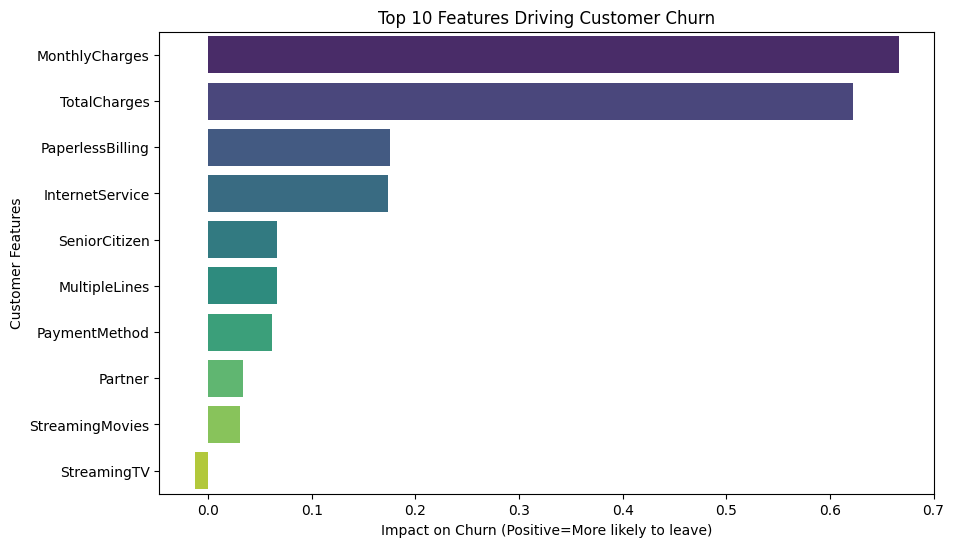

In [6]:
# 4.Business Insight: Feature Importance
coefficients=model.coef_[0]
feature_names=X.columns
# Create a dataframe to sort the results
importance_df=pd.DataFrame({'Feature': feature_names, 'Impact': coefficients})
importance_df=importance_df.sort_values(by='Impact', ascending=False)
# Plot the Top 10 features
plt.figure(figsize=(10,6))
sns.barplot(x='Impact', y='Feature', data=importance_df.head(10),palette='viridis')
plt.title('Top 10 Features Driving Customer Churn')
plt.xlabel('Impact on Churn (Positive=More likely to leave)')
plt.ylabel('Customer Features')
plt.show()